# Ariketa 3.7 — XGBoost vs lehen Neural Network-a 🚀🧠 (EGITEKO)

**Dataset-a:** Spambase — email baten ezaugarriak erabiliz `spam / ez-spam` sailkatzea.

Galdera nagusia:

> **Neural Network bat erabiltzeak automatikoki esan nahi al du tabular data-n emaitza hobea izango dugula?**

Konparatuko ditugu:

```text
XGBoost
   VS
MLP Neural Network
```

Baina helburua **ez da aldez aurretik irabazle bat frogatzea**.

Helburua da:

```text
dataset bera
TRAIN / TEST bera
        ↓
XGBoost
        VS
Neural Network
        ↓
accuracy + training time
        ↓
emaitza interpretatu
```

### Nola lan egin

- 🟢 **KOMENTATU:** azaldu zure hitzekin.
- 🟡 **HUTSUNEAK BETE:** `____` osatu.
- 🔴 **KODETU:** kode-zati labur bat idatzi zerotik.

> Neural Network hau **lehen kontaktua** da. Oraindik ez ditugu neuronak, backpropagation edo sare sakonak sistematikoki ikasiko.


## Denbora-proposamena

```text
0–10 min   → Spambase dataset-a ezagutu
10–20 min  → TRAIN/TEST + preprocessing erabakiak
20–35 min  → XGBoost
35–50 min  → lehen Neural Network-a (MLP)
50–60 min  → emaitzak alderatu
60–75 min  → hausnarketa + BONUS
```

Amaitzen ez bada, BONUS atala utzi daiteke.


# 1 ATALA — Spambase: tabular classification 📧

Spambase dataset-ak email bakoitza zenbakizko ezaugarrien bidez deskribatzen du.

Adibidez, feature-ek neurtzen dute:

```text
zenbait hitzen maiztasuna
zenbait karaktereren maiztasuna
letra larrien sekuentzien ezaugarriak
...
```

Target-a:

```text
0 → ez-spam
1 → spam
```

Dataset-a `OpenML`-tik kargatuko dugu.

> Internet konexioa behar da lehen aldiz dataset-a deskargatzeko.


In [23]:
# ============================================================
# LIBURUTEGIAK
# ============================================================

import sys
import subprocess
import importlib.util
import time

# XGBoost ez badago instalatuta, instalatu.
if importlib.util.find_spec("xgboost") is None:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "xgboost"]
    )

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier

from xgboost import XGBClassifier


# ============================================================
# DATASET-A KARGATU
# ============================================================

data = fetch_openml(
    name="spambase",
    version=1,
    as_frame=True
)

X = data.data.copy()

# OpenML-etik target-a string/categorical moduan etor daiteke.
y = data.target.astype(int)


# ============================================================
# 🟡 HUTSUNEAK BETE — EDA
# ============================================================

print(
    "Shape:",
    X.shape
)

print(
    "\nLehen 5 errenkadak:"
)

display(
    X.head(5)
)

print(
    "\nNull kopurua guztira:",
    X.isnull().sum().sum()
)

print(
    "\nKlase kopuruak:"
)

print(
    y.value_counts().sort_index()
)


# ============================================================
# 🟢 KOMENTATU
# ============================================================
#
# 1. Zenbat errenkada eta feature ditugu?
#
# ERANTZUNA: 4601 errenkada (email) eta 57 feature (shape = (4601, 57)).
#
#
# 2. Feature-ak nagusiki numerikoak al dira?
#
# ERANTZUNA: Bai, 57 feature-ak numerikoak dira (hitz/karaktere maiztasunak eta
# letra larrien sekuentzien neurriak). Ez dago aldagai kategorikorik kodetzeko.
#
#
# 3. Zer motatako ML problema da hau?
#
# ERANTZUNA: Sailkapen bitarra (binary classification), gainbegiratua: 0 = ez-spam, 1 = spam.
# Klaseak nahiko orekatuta daude (2788 / 1813 ≈ %61 / %39).
#


Shape: (4601, 57)

Lehen 5 errenkadak:


,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,word_freq_conference,char_freq_%3B,char_freq_%28,char_freq_%5B,char_freq_%21,char_freq_%24,char_freq_%23,capital_run_length_average,capital_run_length_longest,capital_run_length_total
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.0,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.0,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.0,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.0,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.0,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191


# 2 ATALA — TRAIN / TEST eta preprocessing ✂️⚖️

Bi modeloek **split bera** erabiliko dute.

Horrek konparazioa bidezkoagoa egiten du:

```text
TRAIN bera
TEST bera
```

Baina preprocessing-a ez da berdina:

| Modeloa | Scaling? |
|---|---|
| XGBoost | ❌ Ez da beharrezkoa |
| MLP Neural Network | ✅ Bai, gomendagarria |

Arau ezaguna:

```text
scaler.fit()       → TRAIN bakarrik
scaler.transform() → TRAIN + TEST
```


In [24]:
# ============================================================
# 🟡 TRAIN / TEST
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# ============================================================
# 🟡 NEURAL NETWORK-ERAKO SCALING
# ============================================================

scaler = StandardScaler()

X_train_s = scaler.fit_transform(
    X_train
)

X_test_s = scaler.transform(
    X_test
)


# ============================================================
# 🟢 KOMENTATU
# ============================================================
#
# 1. Zergatik erabiliko dute bi modeloek TRAIN/TEST split bera?
#
# ERANTZUNA:Modeloak justu eta zuzen konparatu ahal izateko. Bi modeloek datu
# berberekin entrenatu eta datu berberekin probatzen badira, emaitzen aldea
# modeloaren ondorioz izango da, eta ez zoriak aukeratutako datuen ondorioz.
# Bestela, modelo batek test multzo "errazagoa" izan lezake, eta konparaketa
# engainagarria litzateke.
#
#
# 2. Zergatik ez dugu XGBoost-erako scaling-a behar?
#
# ERANTZUNA:XGBoost erabaki-zuhaitzetan oinarritzen delako. Zuhaitzek
# feature-aren balioak atalaseekin konparatzen dituzte (adibidez, "x > 0.5?"),
# eta horrek ez du eskalaren menpe egon behar: balioen ordena berdina da
# eskalatu aurretik eta ondoren. Beraz, feature baten tartea 0-1 edo 0-1000
# izateak ez du zuhaitzaren erabakian eragiten.
#
#
# 3. Zergatik da scaling-a garrantzitsua MLP-rako?
#
# ERANTZUNA:MLP-a sare neuronala delako eta gradientearen jaitsieran
# (gradient descent) oinarrituta entrenatzen delako. Feature batzuek
# balio oso handiak badituzte eta beste batzuek oso txikiak, handienek
# pisu gehiegi hartzen dute, entrenamendua ezegonkorra eta motela bihurtzen da,
# eta konbergentzia zailagoa izaten da. Eskalatuz gero (adibidez
# StandardScaler-ekin), feature guztiek tarte antzekoa dute eta sareak
# azkarrago eta hobeto ikasten du.
#
#


# 3 ATALA — XGBoost 🚀🌳

Orain arte ikusi dugu XGBoost-en ideia:

```text
hasierako eredua
    ↓
loss / gradient / pseudo-error
    ↓
zuhaitz berri bat
    ↓
zuzenketa gehitu
    ↓
errepikatu
```

Eta prediction egitean:

```text
datu berria
    ↓
ensemble-ko zuhaitz guztietatik
    ↓
zuzenketak metatu
    ↓
azken score / probability / class
```

Ez dugu tuning sakona egingo. Parametro zentzuzko batzuk finkatuko ditugu.


In [25]:
# ============================================================
# 🔴 KODETU — XGBOOST
# ============================================================
#
# Sortu XGBClassifier parametro hauekin:
#
# n_estimators = 150
# max_depth = 3
# learning_rate = 0.10
# subsample = 0.90
# colsample_bytree = 0.90
# eval_metric = "logloss"
# random_state = 42
# n_jobs = -1
#
# Ondoren:
#
# 1. entrenamendu-denbora neurtu
# 2. fit(X_train, y_train)
# 3. TRAIN eta TEST accuracy kalkulatu

from sklearn.metrics import accuracy_score

# Eredua sortu adierazitako parametroekin
xgb = XGBClassifier(
    n_estimators=150,
    max_depth=3,
    learning_rate=0.10,
    subsample=0.90,
    colsample_bytree=0.90,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# IDATZI HEMEN:
inicio = time.time()
xgb.fit(X_train, y_train)
xgb_time = time.time() - inicio

# 3. Accuracy en TRAIN y TEST
xgb_train = accuracy_score(y_train, xgb.predict(X_train))
xgb_test = accuracy_score(y_test, xgb.predict(X_test))

print(f"Tiempo de entrenamiento: {xgb_time:.2f} s")
print(f"Accuracy TRAIN: {xgb_train:.4f}")
print(f"Accuracy TEST:  {xgb_test:.4f}")







# ============================================================
# 🟢 KOMENTATU
# ============================================================
#
# 1. XGBoost-eko zuhaitzak independenteak al dira?
#
# ERANTZUNA: Ez, ez dira independenteak. XGBoost-ek boosting teknika erabiltzen
# du: zuhaitzak banan-banan eraikitzen dira, eta zuhaitz berri bakoitzak
# uneko ensemble-aren loss-aren gradienteari lotutako errore-seinalea
# (pseudo-residual-ak) modelatzen du, aurrekoen akatsak zuzentzeko. Horregatik,
# zuhaitz bakoitza aurrekoen menpe dago. Hau da Random Forest-en kontrako
# kasua, non zuhaitzak independenteak diren eta paraleloan entrena daitezkeen.
#
#
# 2. Zer egiten du learning_rate-k?
#
# ERANTZUNA:Zuhaitz berri bakoitzaren ekarpena kontrolatzen du, hau da,
# zuhaitz bakoitzak azken iragarpenean zenbateko eragina izango duen.
# Balio txikiak (adibidez 0.1) ikasketa mantsoagoa eta zuhaitz gehiago
# behar dituena egiten du, baina orokorrean overfitting-a saihesten eta
# orokortzea hobetzen laguntzen du. Balio handiak azkarrago ikasten du,
# baina gainjartzeko arriskua handiagoa da.
#


Tiempo de entrenamiento: 3.94 s
Accuracy TRAIN: 0.9707
Accuracy TEST:  0.9425


# 4 ATALA — Gure lehen Neural Network-a 🧠

Oraingoz ez dugu barruko matematika azalduko.

MLP honen egitura:

```text
57 input feature
      ↓
64 neurona
      ↓
32 neurona
      ↓
spam / ez-spam
```

`MLPClassifier` = **Multi-Layer Perceptron**.

Oraingoz nahikoa da hau ulertzea:

> Sareak feature-ak geruzaz geruza eraldatzen ditu azken sailkapena egiteko.

Aurrerago ikasiko dugu:

```text
neurona
weighted sum
activation
loss
gradient descent
backpropagation
epochs
```


In [29]:
# ============================================================
# MLP NEURAL NETWORK
# ============================================================
#
# Kodea EMANDA dago: hau gure lehen sare neuronala da.
#
# Gogoratu:
# X_train_s / X_test_s erabiliko ditugu.

mlp = MLPClassifier(
    hidden_layer_sizes=(
        64,
        32
    ),
    activation="relu",
    solver="adam",
    max_iter=500,
    early_stopping=True,
    random_state=42
)


t0 = time.perf_counter()

mlp.fit(
    X_train_s,
    y_train
)

mlp_time = (
    time.perf_counter()
    - t0
)


mlp_train = mlp.score(
    X_train_s,
    y_train
)

mlp_test = mlp.score(
    X_test_s,
    y_test
)


print(
    "MLP TRAIN accuracy:",
    round(mlp_train, 3)
)

print(
    "MLP TEST accuracy :",
    round(mlp_test, 3)
)

print(
    "Training time:",
    round(mlp_time, 3),
    "s"
)


# ============================================================
# 🟢 KOMENTATU
# ============================================================
#
# 1. hidden_layer_sizes=(64, 32) zer esan nahi du?
#
# ERANTZUNA:Sareak bi geruza ezkutu dituela esan nahi du: lehenengoak 64
# neurona ditu eta bigarrenak 32. Beraz, datuak (57 feature) sarrera-geruzatik
# 64 neuronako geruzara pasatzen dira, gero 32 neuronako geruzara, eta azkenean
# irteera-geruzara (spam ala ez spam). Zenbaki handiagoek sareari ahalmen
# handiagoa ematen diote, baina overfitting-aren arriskua ere handitzen dute.
#
#
# 2. Neural Network honek scaling-a erabili du?
#
# ERANTZUNA:Bai, MLP-ak eskalatutako datuak erabili ditu (X_train_s eta
# X_test_s), StandardScaler-ekin lortuak. Scaler-a TRAIN multzoarekin
# bakarrik doitu da, eta gero TEST multzoari aplikatu zaio, datuen
# "filtrazioa" (data leakage) saihesteko. XGBoost-ek, aldiz, jatorrizko
# datuak erabili ditu.
#
#
#
# 3. Oraindik esan al dezakegu "NN = algoritmo aurreratuagoa = beti hobea"?
#
# ERANTZUNA:Ez. Sare neuronalak ez dira beti hobeak. Datu tabularretan
# (adibidez, spam dataset hau), XGBoost bezalako zuhaitz-ereduek emaitza
# berdinak edo hobeak lor ditzakete, azkarrago entrenatzen dira eta ez dute
# scaling-a behar. Sare neuronalak datu asko, irudiak edo testua bezalako
# arazoetan nabarmentzen dira. Modeloaren aukera arazoaren eta datuen
# araberakoa da, ez algoritmoaren "modernotasunaren" araberakoa. Horregatik
# konparatu behar dira emaitzak (accuracy eta denbora) erabaki aurretik.
#


MLP TRAIN accuracy: 0.948
MLP TEST accuracy : 0.932
Training time: 1.784 s


# 5 ATALA — Konparazioa: zer gertatu da? 📊

Orain bi modeloen emaitzak taula berean jarriko ditugu.

Kontuan hartu:

> **Training time hardware-aren araberakoa da.**

Beraz denbora zenbaki absolutu gisa baino gehiago, esperimentu honetan bi metodoek izan duten kostuaren ideia moduan erabiliko dugu.


,TRAIN accuracy,TEST accuracy,Scaling,Training time (s)
XGBoost,0.971,0.942,Ez,3.942
MLP Neural Network,0.948,0.932,Bai,2.471


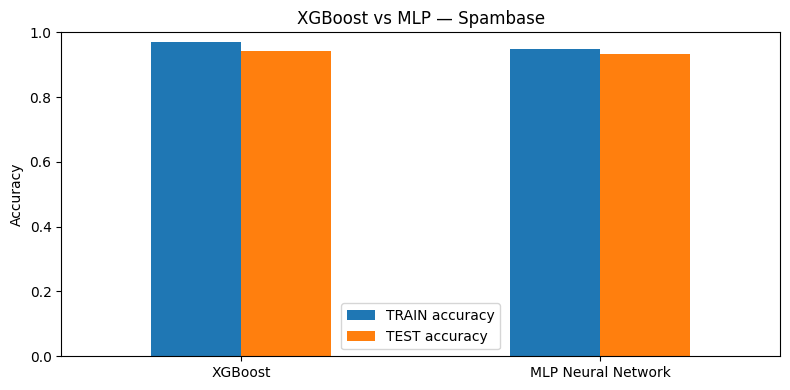

In [27]:
emaitzak = pd.DataFrame({
    "TRAIN accuracy": [
        xgb_train,
        mlp_train
    ],
    "TEST accuracy": [
        xgb_test,
        mlp_test
    ],
    "Scaling": [
        "Ez",
        "Bai"
    ],
    "Training time (s)": [
        xgb_time,
        mlp_time
    ]
}, index=[
    "XGBoost",
    "MLP Neural Network"
])


display(
    emaitzak.round(3)
)


# ============================================================
# GRAFIKOA
# ============================================================

emaitzak[
    ["TRAIN accuracy", "TEST accuracy"]
].plot(
    kind="bar",
    figsize=(8, 4),
    rot=0
)

plt.ylim(
    0,
    1
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "XGBoost vs MLP — Spambase"
)

plt.tight_layout()
plt.show()


# ============================================================
# 🟢 KOMENTATU
# ============================================================
#
# 1. Zeinek lortu du TEST accuracy handiena?
#
# ERANTZUNA: XGBoost-ek lortu du TEST accuracy handiena, 0.942 balioarekin;
# MLP-k 0.932 lortu du.
#
#
# 2. Diferentzia handia ala txikia da?
#
# ERANTZUNA: Diferentzia txikia da: 0.942 - 0.932 = 0.010 (puntu portzentual 1,
# ~9 email 921etik). Bi modeloek
# emaitza antzekoak lortu dituzte, beraz ezin dugu esan benetako alde
# nabarmenik dagoenik. Diferentzia hain txikia izanik, beste TRAIN/TEST
# split batekin edo beste random_state batekin ordena alda liteke.
#
#
# 3. Esperimentu honetatik esan al dezakegu XGBoost beti hobea dela?
#
# ERANTZUNA:Ez. Esperimentu honek datu-multzo bakar batean (spam
# sailkapena) eta konfigurazio zehatz batekin konparatzen ditu modeloak.
# Horrek ez du frogatzen XGBoost beti hobea denik. Beste datu-multzo
# batzuetan, edo beste parametro batzuekin, emaitza desberdina izan liteke.
# Ondorioa soilik esperimentu honi dagokio.
#
#
# 4. Eta MLP-k irabaziko balu, esan al genezake NN-ak beti hobeak direla?
#
# ERANTZUNA:Ez, arrazoi berberengatik. Modelo batek kasu batean irabazteak
# ez du esan nahi beti irabaziko duenik. Datu tabularretan zuhaitz-ereduak
# oso lehiakorrak dira, eta sare neuronalek ez dute berez abantailarik.
# Modeloa aukeratzeko datuak, emaitzak, entrenamendu-denbora eta
# konplexutasuna hartu behar dira kontuan, ez algoritmoaren "fama".
#


# 6 ATALA — 🟢 Azken hausnarketa

Osatu esaldiak zure hitzekin.

### A) XGBoost

> Tabular data-n XGBoost indartsua izan daiteke, zuhaitz txiki asko **sekuentzialki** eraikitzen dituelako eta bakoitzak aurreko ensemble-aren **errorea (loss-aren gradientea / pseudo-residual-ak)** zuzentzen laguntzen duelako.

### B) Neural Network

> MLP-ak input feature-ak geruzaz geruza **eraldatzen / konbinatzen** ditu, baina horrek ez du esan nahi tabular data guztietan automatikoki **hobea** izango denik.

### C) Ondorio nagusia

> “Modelo sofistikatuagoa” ≠ “**modelo** onena”.

**Zein da gaurko ikasgai nagusia?**

ERANTZUNA: Ez dago algoritmo irabazle automatikorik. Spambase-n (datu tabularra) XGBoost-ek 0.942 eta MLP-k 0.932 lortu dute: emaitza ia berdinak. XGBoost-ek ez du scaling-ik behar eta oso lehiakorra da datu tabularretan; sare neuronalak ez dira "modernoagoak" direlako bakarrik hobeak. Modeloa aukeratzeko, dataset eta split berarekin **konparatu** egin behar da (accuracy, denbora, konplexutasuna, interpretabilitatea), eta emaitza esperimentu horri dagokiola onartu.

# BONUS — Sare neuronalaren tamaina aldatzen badugu? 🟣

Denbora baduzu bakarrik.

Konparatu:

```text
(32,)
(64, 32)
(128, 64, 32)
```

Ez dugu tuning formalik egingo.

Galdera:

> **Sare handiagoa = beti TEST accuracy handiagoa?**


In [28]:
arkitekturak = [
    (32,),
    (64, 32),
    (128, 64, 32)
]

lerroak = []

for ark in arkitekturak:

    modeloa = MLPClassifier(
        hidden_layer_sizes=ark,
        activation="relu",
        solver="adam",
        max_iter=500,
        early_stopping=True,
        random_state=42
    )

    t0 = time.perf_counter()

    modeloa.fit(
        X_train_s,
        y_train
    )

    denbora = (
        time.perf_counter()
        - t0
    )

    lerroak.append({
        "architecture": str(ark),
        "TRAIN accuracy": modeloa.score(
            X_train_s,
            y_train
        ),
        "TEST accuracy": modeloa.score(
            X_test_s,
            y_test
        ),
        "time (s)": denbora
    })


display(
    pd.DataFrame(
        lerroak
    ).round(3)
)


# 🟢 KOMENTATU:
#
# Sare handiagoa izateak TEST accuracy beti handitzen al du?
#
# ERANTZUNA: Ez. (32,) → (64, 32) igotzean TEST 0.920 → 0.932 hobetu da, baina
# (128, 64, 32)-rekin TEST berdin geratu da (0.932) TRAIN igo arren (0.948 → 0.952).
# Ahalmen gehiagok train-era gehiago egokitzea ahalbidetzen du (overfitting arriskua),
# baina ez du generalizazioa bermatzen. Sare handiagoa = parametro gehiago, ez
# derrigorrez emaitza hobea.
#


,architecture,TRAIN accuracy,TEST accuracy,time (s)
0,"(32,)",0.918,0.920,0.846
1,"(64, 32)",0.948,0.932,1.842
2,"(128, 64, 32)",0.952,0.932,1.174


# Amaierako ideia ✅

```text
TABULAR DATA
    ↓
ez dago irabazle automatikoa

XGBoost
→ tree-based boosting
→ scaling ez da beharrezkoa
→ oso lehiakorra tabular data-n

MLP
→ lehen Neural Network-a
→ scaling behar du
→ geruzaz geruza feature-ak eraldatzen ditu
→ ez da automatikoki hobea
```

Esaldi nagusia:

> **Datu-motak eta problemaren egiturak asko baldintzatzen dute zein modelo den egokiena.**
